# **Environment Setup and Dependencies**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# **Dataset Acquisition and Loading**

In [2]:
import kagglehub
# Download latest version
path = kagglehub.dataset_download("manishkr1754/cardekho-used-car-data")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cardekho-used-car-data' dataset.
Path to dataset files: /kaggle/input/cardekho-used-car-data


In [3]:
import os
print("Files in dataset:")
for file in os.listdir(path):
    print(file)

Files in dataset:
cardekho_dataset.csv


In [4]:
files = os.listdir(path)
csv_files = [file for file in files if file.endswith(".csv")]
file_path = os.path.join(path, csv_files[0])
real_df = pd.read_csv(file_path)
df = real_df.copy()

# **Initial Data Inspection and Schema Analysis**

In [ ]:
df.shape

(15411, 14)

In [ ]:
df.head()

,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [ ]:
df.tail()

,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
15406,19537,Hyundai i10,Hyundai,i10,9,10723,Dealer,Petrol,Manual,19.81,1086,68.05,5,250000
15407,19540,Maruti Ertiga,Maruti,Ertiga,2,18000,Dealer,Petrol,Manual,17.50,1373,91.10,7,925000
15408,19541,Skoda Rapid,Skoda,Rapid,6,67000,Dealer,Diesel,Manual,21.14,1498,103.52,5,425000
15409,19542,Mahindra XUV500,Mahindra,XUV500,5,3800000,Dealer,Diesel,Manual,16.00,2179,140.00,7,1225000
15410,19543,Honda City,Honda,City,2,13000,Dealer,Petrol,Automatic,18.00,1497,117.60,5,1200000


In [ ]:
df.columns

Index(['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven',
       'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine',
       'max_power', 'seats', 'selling_price'],
      dtype='object')

### Missing-Value Assessment

In [ ]:
df.isna().sum()

,0
Unnamed: 0,0
car_name,0
brand,0
model,0
vehicle_age,0
km_driven,0
seller_type,0
fuel_type,0
transmission_type,0
mileage,0


In [ ]:
df.duplicated().sum()

np.int64(0)

# **Data Visualization and Statistical Analysis**

### 	Feature Distribution and Skewness Analysis

<Axes: xlabel='selling_price', ylabel='Count'>

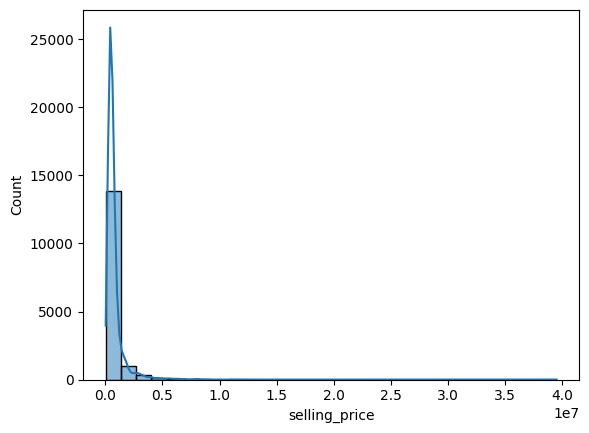

In [ ]:
sns.histplot(data=df, x='selling_price', kde=True, bins=30)

In [ ]:
df['selling_price'].skew()

np.float64(10.047047978435213)

### Univariate Analysis
Numerical Columns

array([[<Axes: title={'center': 'vehicle_age'}>,
        <Axes: title={'center': 'km_driven'}>],
       [<Axes: title={'center': 'mileage'}>,
        <Axes: title={'center': 'engine'}>],
       [<Axes: title={'center': 'max_power'}>,
        <Axes: title={'center': 'seats'}>]], dtype=object)

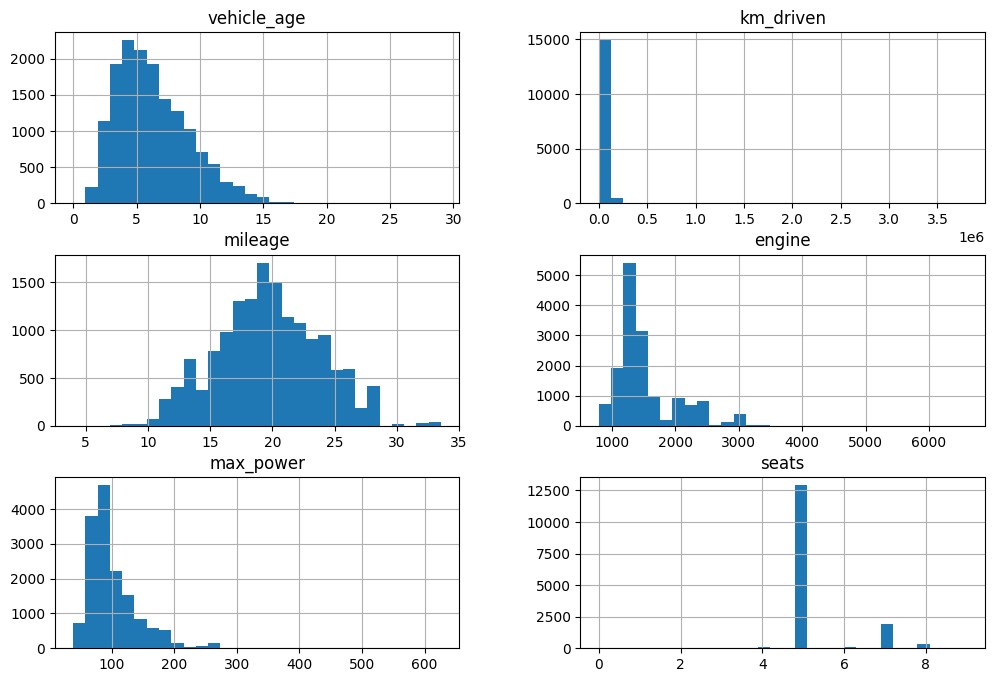

In [ ]:
numerical_columns =['vehicle_age', 'km_driven',  'mileage', 'engine', 'max_power', 'seats']
df[numerical_columns].hist(bins=30, figsize=(12,8))

### Univariate Analysis
Categorical columns

<Axes: xlabel='fuel_type', ylabel='count'>

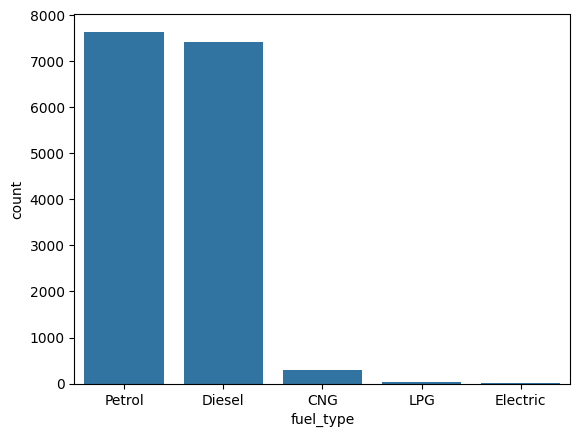

In [ ]:
categorical_columns = ['car_name', 'brand', 'model','seller_type','fuel_type','transmission_type']
sns.countplot(data=df, x='fuel_type')

<Axes: xlabel='fuel_type', ylabel='selling_price'>

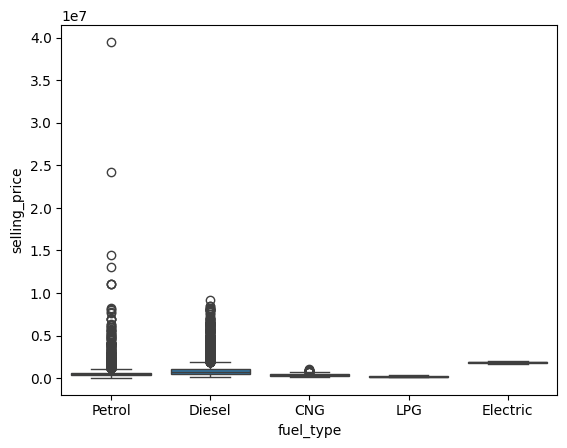

In [ ]:
sns.boxplot(data=df, x='fuel_type', y='selling_price')

<Axes: xlabel='fuel_type', ylabel='selling_price'>

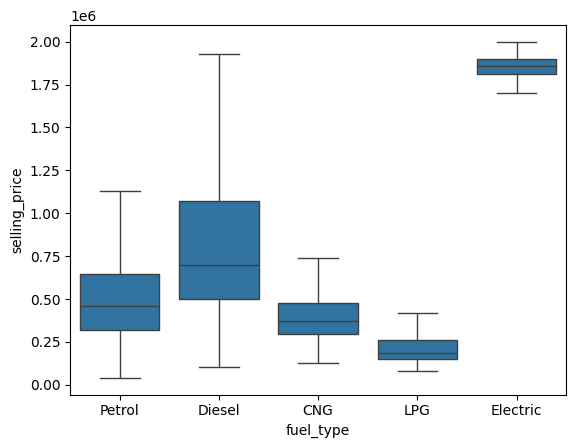

In [ ]:
sns.boxplot(data = df, x='fuel_type', y='selling_price', showfliers=False) # showfliers hide the outliers so you can see the graph more clearly, without deleting them

### Numerical Feature Correlation Analysis

<Axes: >

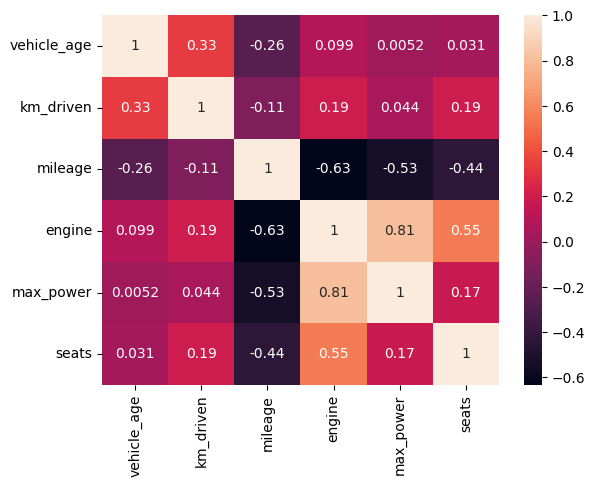

In [ ]:
corr = df[numerical_columns].corr()
sns.heatmap(corr, annot=True)

### Vehicle Age vs. Selling Price Analysis

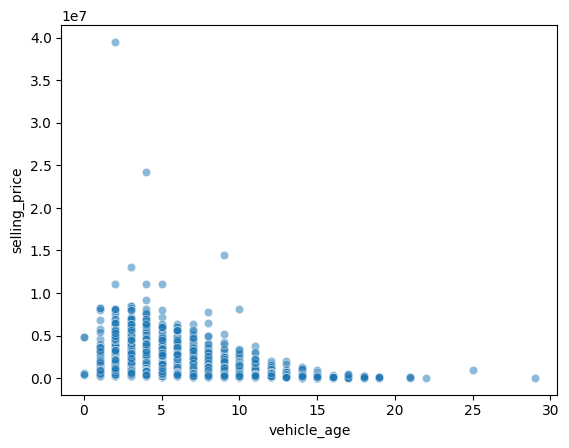

In [ ]:
sns.scatterplot(data = df, x='vehicle_age', y='selling_price', alpha=0.5)
plt.show()

### Selling Price Analysis by Fuel Type

<Axes: xlabel='fuel_type', ylabel='selling_price'>

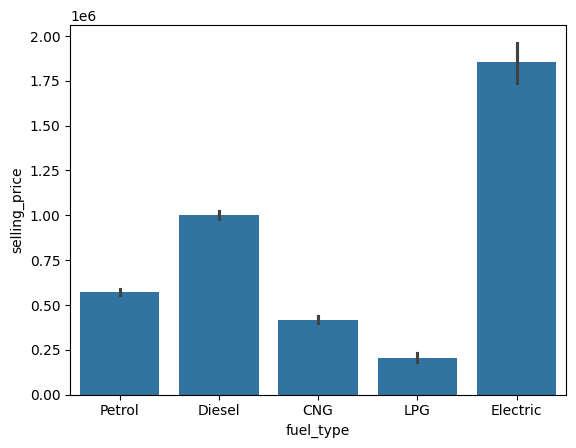

In [ ]:
sns.barplot(data = df, x='fuel_type', y='selling_price')

## **Data Cleaning and Feature Selection**

Dropping columns

In [ ]:
df.drop(columns=['Unnamed: 0'], axis=1, inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(167)

In [ ]:
df[df.duplicated].head()

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
197,Honda City,Honda,City,8,70000,Individual,Petrol,Manual,16.8,1497,116.30,5,545000
360,Maruti Baleno,Maruti,Baleno,2,5000,Individual,Petrol,Automatic,21.4,1197,83.10,5,686000
1353,Maruti Swift Dzire,Maruti,Swift Dzire,4,50000,Individual,Diesel,Manual,28.4,1248,74.02,5,680000
1429,Maruti Wagon R,Maruti,Wagon R,13,100000,Individual,Petrol,Manual,18.9,1061,67.00,5,150000
1485,Hyundai i20,Hyundai,i20,3,50000,Individual,Petrol,Manual,18.6,1197,81.83,5,625000


<Axes: xlabel='vehicle_age', ylabel='selling_price'>

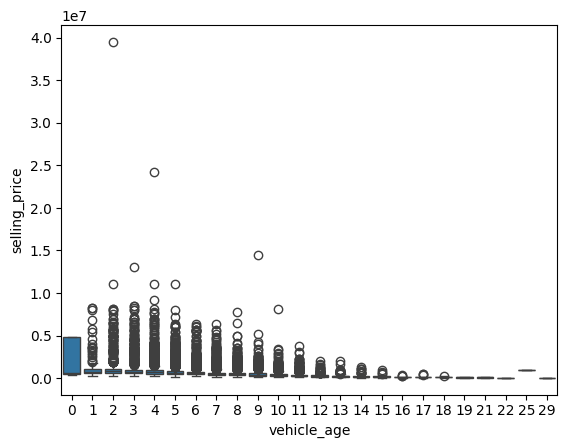

In [ ]:
sns.boxplot(data = df, x='vehicle_age', y='selling_price')

In [ ]:
df.drop_duplicates(inplace=True)

### Outlier Treatment Using Winsorization

In [ ]:
caps = {}
for col in numerical_columns:
  caps[col] = df[col].quantile(0.99)
  df[col] = df[col].clip(upper=caps[col])

# numeric cols here for illustration = ['vehicle_age', 'km_driven', 'selling_price', 'mileage', 'engine', 'max_power', 'seats']

In [ ]:
Q1 = df['selling_price'].quantile(0.25)
Q3 = df['selling_price'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df['selling_price'] < lower) |
    (df['selling_price'] > upper)
]

print(outliers[['car_name', 'selling_price']])
print("Outlier count:", len(outliers))

                    car_name  selling_price
12               Mini Cooper        3250000
58           Mahindra XUV500        1650000
111                    BMW 5        2600000
129           Ford Endeavour        2900000
139                    BMW 3        2090000
...                      ...            ...
15341          Toyota Innova        1640000
15360           Jeep Compass        1750000
15362                  BMW 5        3975000
15384  Mercedes-Benz E-Class        4450000
15397          Toyota Innova        2350000

[1371 rows x 2 columns]
Outlier count: 1371


## 	Feature-Target Separation

In [ ]:
X = df.drop(columns=['selling_price'], axis=1)
y= df['selling_price']

## **Training and Holdout Test Split**

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42)

## **Preprocessing Pipeline and Feature Transformation**

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer, OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

In [ ]:
numeric_pipeline = Pipeline(steps= [
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])

categorical_pipeline = Pipeline(steps = [
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers = [
    ('numeric', numeric_pipeline, numerical_columns),
    ('categorical', categorical_pipeline, categorical_columns)
])

preprocessor

ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['vehicle_age', 'km_driven', 'mileage',
                                  'engine', 'max_power', 'seats']),
                                ('categorical',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encode',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['car_name', 'brand', 'model', 'seller_type',
                                  'fuel_type', 'transmission_type'])])

In [ ]:
df[numerical_columns].skew()

,0
vehicle_age,0.719198
km_driven,1.092602
mileage,0.009068
engine,1.312541
max_power,1.677120
seats,1.944321


## **Comparative Model Evaluation**
- DecisionTreeRegressor
- LinearRegression
- RandomForestRegressor
- GradientBoostingRegressor
-ExtraTreesRegressor

In [ ]:
from sklearn.model_selection import cross_validate, KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import(
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)

In [ ]:
models = {
    "Linear Regression" : LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest" : RandomForestRegressor(n_estimators=200, random_state=42, n_jobs= -1), # n_estimators -> means you can make 200 trees, and n_job = -1 means in your laptop, you have some cores which handles each and every task, so -1 means use all cores of my laptop and make all 200 trees parallely saving some time, but using it +1, means make one tree, see it's answer, then make another tree and so on till 200, and if set it -2, then it will be like - telling the laptop to - leave 1 core for any other current tasks running on the laptop right now and then taka other cores for processing.
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=200, random_state=42, n_jobs= -1) # works exactly as random_forest, diff is - split selection
}
cv = KFold(n_splits=5, shuffle=True, random_state=42) # As we use cross_val_score in classification problems, here we use KFold for the same task, Shuffle = True means data is randomly rearranged before splitting

results =[]

for name, model in models.items():
  pipe = Pipeline([
      ("preprocessor", preprocessor),
      ("model", model)
  ])
  scores = cross_validate(
    pipe, X_train, y_train, cv=cv, scoring = {
         # mae also in small value as possible
        "mae" : "neg_mean_absolute_error", # calcultes the avg diff between the real price and your models' predicted price
         # rmse value small as possible
        "rmse" : "neg_root_mean_squared_error", # Same above technique, but penlizes big number errors
        "r2": "r2"
    },
    n_jobs = -1
  )

  results.append({
      "Model": name,
      "MAE": -scores["test_mae"].mean(),
      "RMSE": -scores["test_rmse"].mean(),
      "R2": scores["test_r2"].mean()
  })

result_df = pd.DataFrame(results)
print(result_df.sort_values("MAE"))

               Model            MAE           RMSE        R2
2      Random Forest  102045.227119  331845.030269  0.864406
4        Extra Trees  103826.582845  341359.032194  0.854563
3  Gradient Boosting  127297.727581  360886.760087  0.841845
1      Decision Tree  128486.417248  384922.814259  0.822839
0  Linear Regression  182851.163675  507835.631882  0.692559


## 	**Baseline Random Forest Evaluation**

In [ ]:
  best_pipeline_wo_hpt = Pipeline(steps = [
      ("preprocessor", preprocessor),
      ("model", RandomForestRegressor(random_state=42))
  ])

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)
best_pipeline_wo_hpt.fit(X_train, y_train)
y_pred_rfr = best_pipeline_wo_hpt.predict(X_test)
print(f"MSE : {mean_absolute_error(y_test, y_pred_rfr)}")
print(f"RMSE : {root_mean_squared_error(y_test, y_pred_rfr)}")
print(f"R2 : {r2_score(y_test, y_pred_rfr)}")

MSE : 98486.40005832512
RMSE : 209336.60350625255
R2 : 0.9279271171635808


## **Hyperparameter Optimization**

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

best_pipeline_w_hpt = Pipeline(steps = [
    ("preprocessor", preprocessor),
    ("model_2", RandomForestRegressor(random_state=42))
])

param_distributions = {
    "model_2__n_estimators" : [100,200,300,500],
    "model_2__max_depth":[None, 1,20,30],
    "model_2__min_samples_split" :[2,5,10],
    "model_2__min_samples_leaf" : [1,2,4]
}
best_pipe_rfr = RandomizedSearchCV(
    estimator = best_pipeline_w_hpt,
    param_distributions = param_distributions,
    n_iter = 10,
     cv= 5,
    scoring = "neg_root_mean_squared_error",
    random_state = 42,
    n_jobs = -1
)
# verbos =2, add this to the above randomizesearchcv(), so the next time it will show you exactly where you are..

best_pipe_rfr.fit(X_train, y_train)
y_prediction_rfr = best_pipe_rfr.predict(X_test)

print(f"MAE : {mean_absolute_error(y_test, y_prediction_rfr)}")
print(f"RMSE : {root_mean_squared_error(y_test, y_prediction_rfr)}")
print(f"r2: {r2_score(y_test, y_prediction_rfr)}")

MAE : 96362.8836936548
RMSE : 209230.96153266987
r2: 0.927999842145927


In [ ]:
best_pipe_rfr.best_params_

{'model_2__n_estimators': 200,
 'model_2__min_samples_split': 10,
 'model_2__min_samples_leaf': 1,
 'model_2__max_depth': 30}

## **Model Serialization and Artifact Management**

In [ ]:
import joblib
joblib.dump(
    best_pipe_rfr.best_estimator_,
    "best_random_forest.pkl"
)

['best_random_forest.pkl']